# Propagate a seeded uncertainty design

**Question:** How does the propagate a seeded uncertainty design analysis change when the same authored ore is run at controlled throughput settings?

Level: 2. Prerequisites: Level 1 of this topic and level 2 of comminution. Reading time: 30 minutes.

## Objectives

Run OreFlow's uncertainty function on a teaching-sized seeded design, inspect the simulated recovery distribution and compare the nominal point with its sampled range.

## Setup

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0 SALib==1.6.0
```

The OreFlow pipeline is imported from `data-pipeline/`; this notebook never installs packages.

Configure imports and record versions. This makes the method run reproducible.

In [1]:
# Import analysis tools and record their exact versions.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resolve the local pipeline from the repository-relative layout.
repo = Path("../../../").resolve()
sys.path.insert(0, str(repo / "data-pipeline"))
for package in ("numpy", "scipy", "pandas", "matplotlib", "nbclient", "nbformat", "ipykernel"):
    print(package, importlib.metadata.version(package))


numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Data

Owner: OreFlow authors; the scenario, contract bounds and uncertainty assumptions are in `data/derived/cases/copper_porphyry_soft.json`, `data/derived/contract/operating_contract.json` and `data/derived/benchmark.json`, MIT project licence. Repository: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Method

The production method maps a deterministic Latin-hypercube design through OreFlow's `perturbed` and `_evaluate` functions, which call the process solver. Rejected steady states are counted rather than silently turned into measurements. This lesson uses 32 runs for an inspectable teaching exercise; the committed record uses the production sample count.

Run the product uncertainty method with a fixed seed and a small sample count for a quick, repeatable experiment.

In [2]:
from pipeline.cases.catalog import CASES
from pipeline.methods.uncertainty import uncertainty

# Use the production uncertainty implementation on one authored circuit.
case = next(item for item in CASES if item.id == "copper_porphyry_soft")
experiment = uncertainty(case, case.nominal, samples=32, seed=20261027)
print(
    "samples:",
    experiment["samples"],
    "| seed:",
    experiment["seed"],
    "| solved:",
    len(experiment["solved"]),
)
print("refused:", experiment["refused"])
print("input half-widths:", experiment["inputs"])


samples: 32 | seed: 20261027 | solved: 32
refused: {}
input half-widths: {'work_index': {'half_width': 0.2}, 'head_grade': {'half_width': 0.2}, 'liberation_size': {'half_width': 0.25}, 'floatability': {'half_width': 0.25}}


Plot solved recovery draws and mark the nominal engine result. The histogram is conditional on this scenario and input envelope.

P05/P50/P95: [89.47438797 91.87000065 93.45258867]


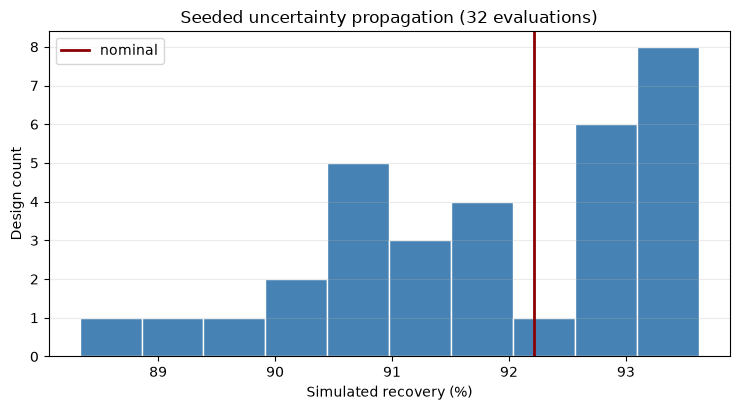

In [3]:
# Plot solved recovery draws and mark the nominal engine result.
recovery = np.asarray(experiment["outputs"]["recovery_pct"]["values"], dtype=float)
nominal = case.nominal
from pipeline.engine.circuit import simulate

nominal_result = simulate(case.ore, case.plant, nominal)
nominal_recovery = nominal_result.metrics["recovery_pct"]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.hist(recovery, bins=10, color="steelblue", edgecolor="white")
ax.axvline(nominal_recovery, color="darkred", linewidth=2, label="nominal")
ax.set(
    xlabel="Simulated recovery (%)",
    ylabel="Design count",
    title="Seeded uncertainty propagation (32 evaluations)",
)
ax.grid(True, axis="y", alpha=0.25)
ax.legend()
fig.tight_layout()
print("P05/P50/P95:", np.quantile(recovery, [0.05, 0.5, 0.95]))


Check reproducibility by rerunning the same seed and comparing the design and recovery values exactly.

Figure 11 in level 2 05 uncertainty summarizes solved OreFlow circuits at the stated settings. The connecting line guides comparison only; it is not a fitted response law or confidence band. Check the axes against the contract and paired outputs for this operating question.

In [4]:
# Check reproducibility by rerunning the same seed and comparing the design and recovery values
# exactly.
repeat = uncertainty(case, case.nominal, samples=32, seed=20261027)
print("design identical:", experiment["design"] == repeat["design"])
print(
    "recoveries identical:",
    experiment["outputs"]["recovery_pct"] == repeat["outputs"]["recovery_pct"],
)
print("constraint probabilities:", experiment["probabilities"])


design identical: True
recoveries identical: True
constraint probabilities: {'grade_meets_spec': 1.0, 'power_within_installed': 0.8125, 'water_within_capacity': 1.0, 'all_constraints': 0.8125}


For the level 2 05 uncertainty case, only fresh-feed rate changes at 0.8 times nominal throughput. This level 2 05 uncertainty comparison at 0.8 times nominal feed uses recovery, product P80 and energy to assess the stated constraints.

In [5]:
# Re-solve the authored case at one controlled throughput setting.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
factor_1 = 0.8
point_1 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor_1)
response_1 = simulate(case.ore, case.plant, point_1)
print('throughput (t/h):', round(point_1.throughput_tph, 2))
print('recovery (%):', round(response_1.metrics['recovery_pct'], 3))
print('product P80 (µm):', round(response_1.metrics['p80_um'], 2))

throughput (t/h): 576.0
recovery (%): 93.788
product P80 (µm): 150.0


For the level 2 05 uncertainty case, only fresh-feed rate changes at 0.9 times nominal throughput. This level 2 05 uncertainty comparison at 0.9 times nominal feed uses recovery, product P80 and energy to assess the stated constraints.

In [6]:
# Re-solve the authored case at one controlled throughput setting.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
factor_2 = 0.9
point_2 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor_2)
response_2 = simulate(case.ore, case.plant, point_2)
print('throughput (t/h):', round(point_2.throughput_tph, 2))
print('recovery (%):', round(response_2.metrics['recovery_pct'], 3))
print('product P80 (µm):', round(response_2.metrics['p80_um'], 2))

throughput (t/h): 648.0
recovery (%): 92.996
product P80 (µm): 150.0


For the level 2 05 uncertainty case, only fresh-feed rate changes at 1.0 times nominal throughput. This level 2 05 uncertainty comparison at 1.0 times nominal feed uses recovery, product P80 and energy to assess the stated constraints.

In [7]:
# Re-solve the authored case at one controlled throughput setting.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
factor_3 = 1.0
point_3 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor_3)
response_3 = simulate(case.ore, case.plant, point_3)
print('throughput (t/h):', round(point_3.throughput_tph, 2))
print('recovery (%):', round(response_3.metrics['recovery_pct'], 3))
print('product P80 (µm):', round(response_3.metrics['p80_um'], 2))

throughput (t/h): 720.0
recovery (%): 92.213
product P80 (µm): 150.0


For the level 2 05 uncertainty case, only fresh-feed rate changes at 1.1 times nominal throughput. This level 2 05 uncertainty comparison at 1.1 times nominal feed uses recovery, product P80 and energy to assess the stated constraints.

In [8]:
# Re-solve the authored case at one controlled throughput setting.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
factor_4 = 1.1
point_4 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor_4)
response_4 = simulate(case.ore, case.plant, point_4)
print('throughput (t/h):', round(point_4.throughput_tph, 2))
print('recovery (%):', round(response_4.metrics['recovery_pct'], 3))
print('product P80 (µm):', round(response_4.metrics['p80_um'], 2))

throughput (t/h): 792.0
recovery (%): 91.437
product P80 (µm): 150.0


For the level 2 05 uncertainty case, only fresh-feed rate changes at 1.2 times nominal throughput. This level 2 05 uncertainty comparison at 1.2 times nominal feed uses recovery, product P80 and energy to assess the stated constraints.

In [9]:
# Re-solve the authored case at one controlled throughput setting.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
factor_5 = 1.2
point_5 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor_5)
response_5 = simulate(case.ore, case.plant, point_5)
print('throughput (t/h):', round(point_5.throughput_tph, 2))
print('recovery (%):', round(response_5.metrics['recovery_pct'], 3))
print('product P80 (µm):', round(response_5.metrics['p80_um'], 2))

throughput (t/h): 864.0
recovery (%): 88.442
product P80 (µm): 165.93


For level 2 05 uncertainty, the panels use identical settings and 5 solved model points rather than plant observations. At level 2, the 05 uncertainty trend is a local response from one authored case and can change near power or grade constraints; it is not a causal plant estimate.

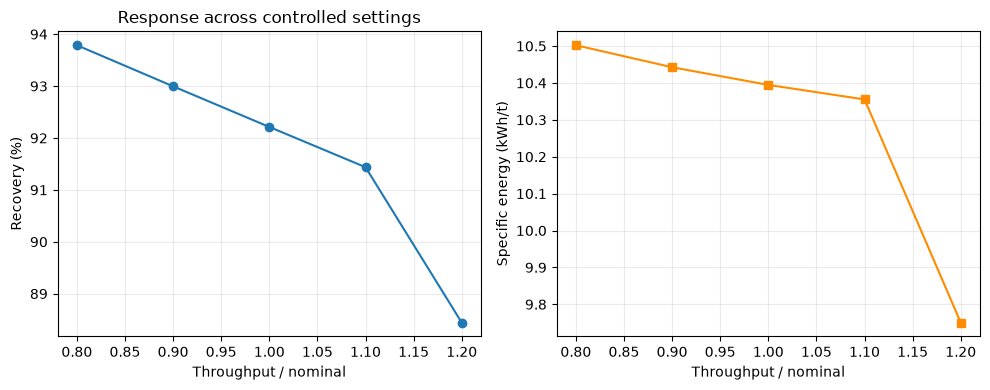

In [10]:
# Compare recovery and specific energy from the executed circuit runs.
import matplotlib.pyplot as plt
factors = [0.8, 0.9, 1.0, 1.1, 1.2]
runs = [response_1, response_2, response_3, response_4, response_5]
recovery = [run.metrics['recovery_pct'] for run in runs]
energy = [run.metrics['specific_energy_total_kwh_t'] for run in runs]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(factors, recovery, marker='o')
axes[0].set(xlabel='Throughput / nominal', ylabel='Recovery (%)', title='Response across controlled settings')
axes[1].plot(factors, energy, marker='s', color='darkorange')
axes[1].set(xlabel='Throughput / nominal', ylabel='Specific energy (kWh/t)')
for axis in axes:
    axis.grid(True, alpha=0.25)
fig.tight_layout()

In the level 2 05 uncertainty analysis, read this size response alongside the recovery and energy panels rather than as a substitute. At level 2, a constant grind target in this 05 uncertainty case can keep P80 nearly unchanged while power limits, recycle and residence alter other outputs. For 05 uncertainty at level 2, retain model flags and the mass-balance audit with the result.

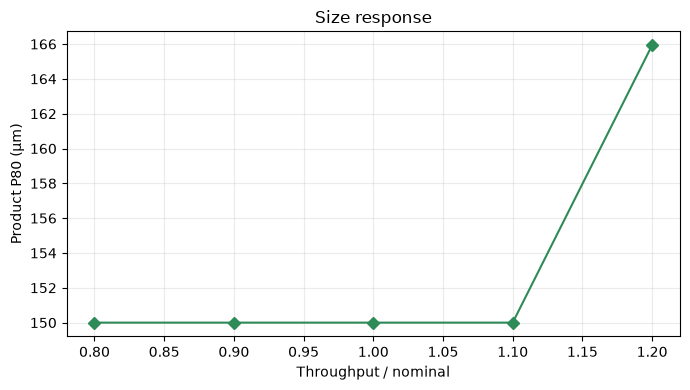

In [11]:
# Show product size separately because it is measured in micrometres, not energy or recovery.
fig, ax = plt.subplots(figsize=(7, 4))
sizes = [run.metrics['p80_um'] for run in runs]
ax.plot(factors, sizes, marker='D', color='seagreen')
ax.set(xlabel='Throughput / nominal', ylabel='Product P80 (µm)', title='Size response')
ax.grid(True, alpha=0.25)
fig.tight_layout()

At level 2 in 05 uncertainty, interpretation 1 is that a scenario spread is conditional on the chosen distributions, dependence assumptions, sample design and process equations. At level 2 in 05 uncertainty, interpretation 2 is that oreFlow's uncertainty propagation samples bounded operating and ore factors, runs the exact circuit engine and summarizes response quantiles and constraint probabilities. At level 2 in 05 uncertainty, interpretation 3 is that a Sobol decomposition asks how input variation contributes to output variance under its sampling assumptions. At level 2 in 05 uncertainty, interpretation 4 is that it does not assign probabilities to the ore body or establish causation. At level 2 in 05 uncertainty, interpretation 5 is that first-order and total-order indices answer different questions because total order includes interactions. At level 2 in 05 uncertainty, interpretation 6 is that bootstrap half-widths describe estimator stability for the design, not uncertainty about the real plant. At level 2 in 05 uncertainty, interpretation 7 is that always report the random seed, base sample count, input bounds, rejected draws and whether output was constant at numerical tolerance. At level 2 in 05 uncertainty, interpretation 8 is that independent draws can create physically implausible combinations when geological variables co-vary, while narrow bounds can make an influential factor appear unimportant. At level 2 in 05 uncertainty, interpretation 9 is that separate input uncertainty from uncertain model structure and measurement error. At level 2 in 05 uncertainty, interpretation 10 is that to interpret a decision, propagate calibrated distributions, compare predicted intervals with held-out plant campaigns and assess whether the ranking of operating choices is stable. At level 2 in 05 uncertainty, interpretation 11 is that the present authored scenarios support method inspection and reproducibility only. At level 2 in 05 uncertainty, interpretation 12 is that they do not provide a probability forecast for a mine or plant.

## Results

**Answer:** In this level 2 05 uncertainty lesson, the executed circuit reports recovery of 93.788 percent at the first controlled throughput setting for Propagate a seeded uncertainty design.

The histogram displays 32 engine-generated outcomes under the selected factors. A repeated seed confirms determinism. The sample is deliberately smaller than the committed record, so its quantiles and probabilities are noisier and are not plant confidence bounds.

## Summary

You executed a deterministic uncertainty propagation through the production engine and checked its sensitivity to the chosen finite design. A reproducible simulation remains conditional on its assumptions.

## References

- https://doi.org/10.1080/00401706.1979.10489755